## Assess Bias and RMSE
A notebook for assessing bias and RMSE of a model's predictions.

In [1]:
import pandas as pd
from buildforcing.datasets import PNNLSnotel
import matplotlib.pyplot as plt
import os

In [2]:
# Load the RMSE and bias csv files
cm_data = pd.read_csv('NMAZsites_s00000000_cmbc_v0.2.1.csv', index_col=0)
gl_data = pd.read_csv('NMAZsites_s00000000_gbc_v0.2.1.csv', index_col=0)
gl_Tcor_data = pd.read_csv('NMAZsites_s00000000_gbc_v0001.csv', index_col=0)

isAlpine=True

In [3]:
# Configure environmental variables
if isAlpine:
    os.environ['OUTPUT_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    SNOTEL_PATH = r'/projects/ccox1@xsede.org/data/snotel/'
    NLDAS_PATH = r'/projects/ccox1@xsede.org/data/nldas/'
    os.environ['FORCING_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/forcing/'

In [4]:
# Calculate the mean RMSE and bias for each dataset
cm_mean_rmse = cm_data['rmse'].mean()
cm_mean_bias = cm_data['bias'].mean()
gl_mean_rmse = gl_data['rmse'].mean()
gl_mean_bias = gl_data['bias'].mean()
gl_Tcor_mean_rmse = gl_Tcor_data['rmse'].mean()
gl_Tcor_mean_bias = gl_Tcor_data['bias'].mean()
print(f"CM Mean RMSE: {cm_mean_rmse}, Mean Bias: {cm_mean_bias}")
print(f"GL Mean RMSE: {gl_mean_rmse}, Mean Bias: {gl_mean_bias}")
print(f"GL Tcor Mean RMSE: {gl_Tcor_mean_rmse}, Mean Bias: {gl_Tcor_mean_bias}")

CM Mean RMSE: 80.6, Mean Bias: -38.949999999999996
GL Mean RMSE: 75.34807692307692, Mean Bias: -34.85961538461538
GL Tcor Mean RMSE: 73.66730769230769, Mean Bias: -33.473076923076924


### Check trends with elevation

In [5]:
# Load the snotel summary file
snotel_summary = pd.read_csv(os.path.join(SNOTEL_PATH,'bcqc_data_v2','SNOTEL_summary.csv'), index_col=0)
#snotel_summary = pd.read_csv('C:/Users/clmbn/NMT_PhD/data/snotel/bcqc_data_v2/SNOTEL_summary.csv', index_col=0)
#snotel_summary = pd.read_csv('/home/chriscox/Data/snotel/bcqc_data_v2/SNOTEL_summary.csv', index_col=0)

In [6]:
# Create single bias and RMSE dataframes for plotting
rmse_df = pd.merge(
    cm_data[['rmse']],
    gl_data[['rmse']],
    left_index=True,
    right_index=True,
    suffixes=('_cm', '_gl')
)
rmse_df = pd.merge(
    rmse_df,
    gl_Tcor_data[['rmse']],
    left_index=True,
    right_index=True
).rename(columns={'rmse': 'rmse_gl_Tcor'})

bias_df = pd.merge(
    cm_data[['bias']],
    gl_data[['bias']],
    left_index=True,
    right_index=True,
    suffixes=('_cm', '_gl')
)

bias_df = pd.merge(
    bias_df,
    gl_Tcor_data[['bias']],
    left_index=True,
    right_index=True
).rename(columns={'bias': 'bias_gl_Tcor'})

In [7]:
rmse_df['elevation_ft'] = snotel_summary.set_index('SNOTEL Name').loc[rmse_df.index, 'SNOTEL Elev (ft)'].values
bias_df['elevation_ft'] = snotel_summary.set_index('SNOTEL Name').loc[bias_df.index, 'SNOTEL Elev (ft)'].values

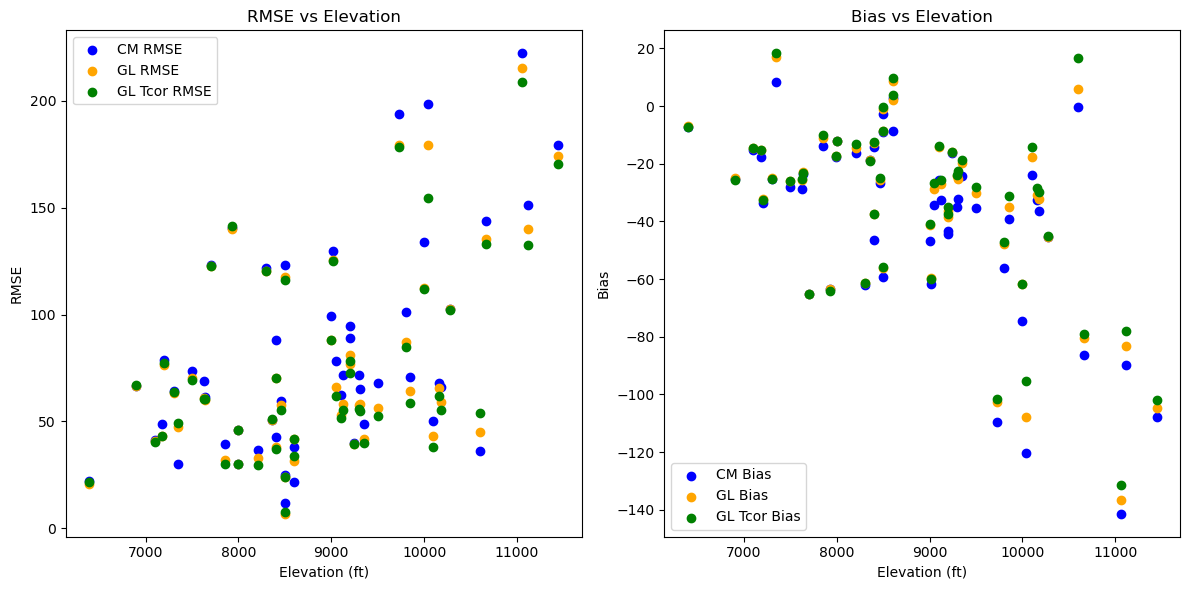

In [8]:
# Plot trends with elevation
plt.figure(figsize=(12, 6))

# RMSE subplot
plt.subplot(1, 2, 1)
plt.scatter(rmse_df['elevation_ft'], rmse_df['rmse_cm'], label='CM RMSE', color='blue')
plt.scatter(rmse_df['elevation_ft'], rmse_df['rmse_gl'], label='GL RMSE', color='orange')
plt.scatter(rmse_df['elevation_ft'], rmse_df['rmse_gl_Tcor'], label='GL Tcor RMSE', color='green')
plt.xlabel('Elevation (ft)')
plt.ylabel('RMSE')
plt.title('RMSE vs Elevation')
plt.legend()

# Bias subplot
plt.subplot(1, 2, 2)
plt.scatter(bias_df['elevation_ft'], bias_df['bias_cm'], label='CM Bias', color='blue')
plt.scatter(bias_df['elevation_ft'], bias_df['bias_gl'], label='GL Bias', color='orange')
plt.scatter(bias_df['elevation_ft'], bias_df['bias_gl_Tcor'], label='GL Tcor Bias', color='green')
plt.xlabel('Elevation (ft)')
plt.ylabel('Bias')
plt.title('Bias vs Elevation')
plt.legend()

plt.tight_layout()
plt.show()

There is a clear trend with elevation, even with downscaled temperatures. I wonder if the difference between SNOTEL and NLDAS elevation is more significant at higher elevations.

In [9]:
# Load the NLDAS elevation netcdf file
import xarray as xr
nldas_elevation = xr.open_dataset(os.path.join(NLDAS_PATH,'NLDAS_elevation.nc4'))
#nldas_elevation = xr.open_dataset('/home/chriscox/Data/nldas/NLDAS_elevation.nc4')

In [10]:
nldas_elevation

<xarray.Dataset> Size: 2MB
Dimensions:         (time: 1, bnds: 2, lat: 224, lon: 464)
Coordinates:
  * lon             (lon) float32 2kB -124.9 -124.8 -124.7 ... -67.19 -67.06
  * lat             (lat) float32 896B 25.06 25.19 25.31 ... 52.69 52.81 52.94
  * time            (time) datetime64[ns] 8B 2000-01-01
Dimensions without coordinates: bnds
Data variables:
    time_bnds       (time, bnds) datetime64[ns] 16B ...
    NLDAS_elev      (time, lat, lon) float32 416kB ...
    NLDAS_elev_std  (time, lat, lon) float32 416kB ...
    NLDAS_elev_max  (time, lat, lon) float32 416kB ...
    NLDAS_elev_min  (time, lat, lon) float32 416kB ...
    NLDAS_slope     (time, lat, lon) float32 416kB ...
    NLDAS_aspect    (time, lat, lon) float32 416kB ...
Attributes: (12/13)
    missing_value:          -9999.0
    time_definition:        constant
    title:                  NLDAS elevation, slope, and aspect
    institution:            NASA GSFC
    history:                created on date: Fri Mar  8 15:58:21 2019
    references:             Mitchell_etal_JGR_2004; Xia_etal_JGR_2012
    ...                     ...
    website:                https://ldas.gsfc.nasa.gov/nldas/
    MAP_PROJECTION:         EQUIDISTANT CYLINDRICAL
    SOUTH_WEST_CORNER_LAT:  25.0625
    SOUTH_WEST_CORNER_LON:  -124.9375
    DX:                     0.125
    DY:                     0.125

In [11]:
# Extract elevations from the NLDAS dataset using latitude and longitude from cm_data
lats = cm_data['latitude'].values
lons = cm_data['longitude'].values

elevations = nldas_elevation.sel(
    lat=xr.DataArray(lats, dims="points"),
    lon=xr.DataArray(lons, dims="points"),
    method="nearest"
)["NLDAS_elev"].values[0]

In [12]:
# Combine NLDAS elevations with rmse_df and bias_df
rmse_df['nldas_elevation_ft'] = elevations * 3.28084  # Convert meters to feet
bias_df['nldas_elevation_ft'] = elevations * 3.28084  # Convert meters to feet

In [13]:
# Calculate differences between NLDAS and SNOTEL elevations
rmse_df['elevation_diff'] = rmse_df['nldas_elevation_ft'] - rmse_df['elevation_ft']
bias_df['elevation_diff'] = bias_df['nldas_elevation_ft'] - bias_df['elevation_ft']

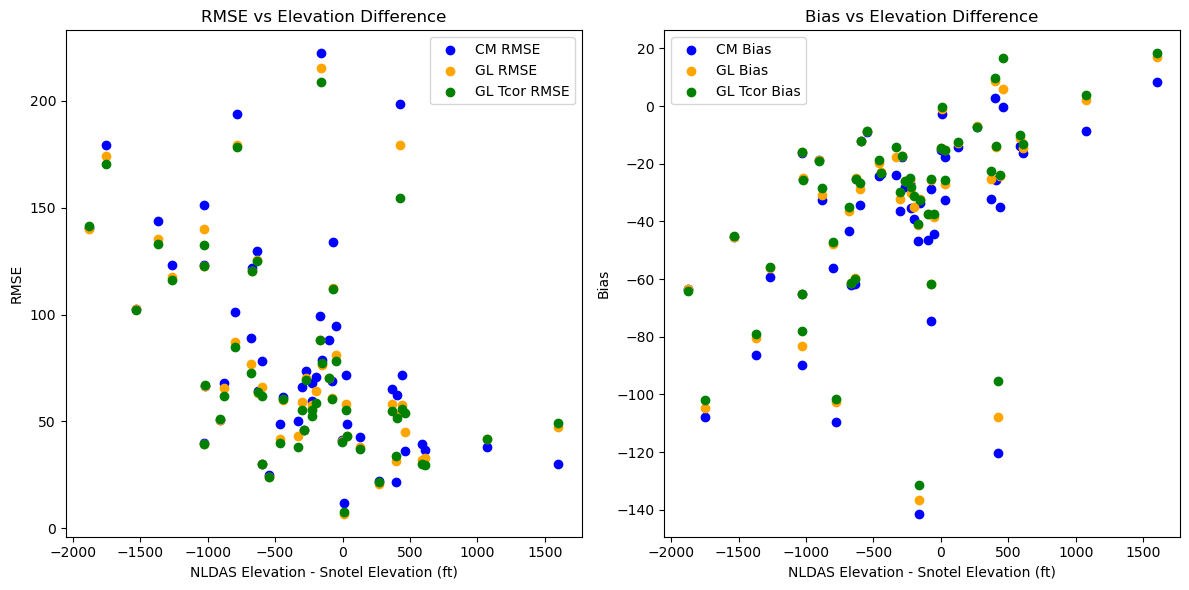

In [14]:
# Plot trends with NLDAS elevation differences
plt.figure(figsize=(12, 6))
# RMSE subplot
plt.subplot(1, 2, 1)
plt.scatter(rmse_df['elevation_diff'], rmse_df['rmse_cm'], label='CM RMSE', color='blue')
plt.scatter(rmse_df['elevation_diff'], rmse_df['rmse_gl'], label='GL RMSE', color='orange')
plt.scatter(rmse_df['elevation_diff'], rmse_df['rmse_gl_Tcor'], label='GL Tcor RMSE', color='green')
plt.xlabel('NLDAS Elevation - Snotel Elevation (ft)')
plt.ylabel('RMSE')
plt.title('RMSE vs Elevation Difference')
plt.legend()

# Bias subplot
plt.subplot(1, 2, 2)
plt.scatter(bias_df['elevation_diff'], bias_df['bias_cm'], label='CM Bias', color='blue')
plt.scatter(bias_df['elevation_diff'], bias_df['bias_gl'], label='GL Bias', color='orange')
plt.scatter(bias_df['elevation_diff'], bias_df['bias_gl_Tcor'], label='GL Tcor Bias', color='green')
plt.xlabel('NLDAS Elevation - Snotel Elevation (ft)')
plt.ylabel('Bias')
plt.title('Bias vs Elevation Difference')
plt.legend()

plt.tight_layout()
plt.show()